# Projeto Final de AVD — Parte Específica: The Complete Pokémon Dataset
## Análise Exploratória de Dados (EDA), Agrupamento com K-Means e Avaliação de Métricas

Este notebook compõe a **Parte Específica** do Projeto Final de Análise e Visualização de Dados (AVD — 2026.2).
O dataset utilizado é o **The Complete Pokemon Dataset** (Rounak Banik / Kaggle), contendo informações completas sobre 801 Pokémons das Gerações 1 a 7.

### Objetivos do Estudo:
1. **Exploração e Limpeza de Dados:** Compreender a distribuição dos atributos base de combate (HP, Attack, Defense, Sp. Atk, Sp. Def, Speed e Base Total), tipos e características dos Pokémons.
2. **Engenharia e Pré-processamento:** Tratar valores ausentes e padronizar as variáveis numéricas com `StandardScaler`.
3. **Agrupamento com K-Means:** Descobrir arquétipos naturais de combate (ex: Tanques Defensivos, Atacantes Rápidos, Estágios Iniciais e Lendários/Titãs).
4. **Métricas de Validação:** Avaliar a qualidade dos agrupamentos utilizando Método do Cotovelo (Inércia), Coeficiente de Silhueta e Índice Davies-Bouldin.
5. **Interpretação e Visualização:** Reduzir a dimensionalidade com PCA e traçar o perfil de cada cluster.

## 1. Pergunta de Pesquisa, Público-Alvo e Storytelling

> *[IA] Claude (Antigravity) – rascunho estruturado a partir das análises do notebook; revisado e validado pelo grupo.*

### Pergunta de pesquisa
**O aumento do poder de combate (`base_total`) ao longo das 7 gerações — o chamado *power creep* — atinge os Pokémon comuns ou é explicado pela maior presença de lendários nas gerações mais recentes?**

Perguntas de apoio respondidas pelo agrupamento:
- Os atributos de combate formam arquétipos naturais (K-Means)?
- O arquétipo de maior poder ("Titãs") é dominado por lendários, e sua participação muda entre gerações?

### Público-alvo
Jogadores e entusiastas de Pokémon (casuais e competitivos iniciantes) e criadores de conteúdo sobre a franquia — público **não técnico**.
Por isso, os gráficos **explanatórios** usam linguagem simples, títulos que afirmam a mensagem e nenhum jargão estatístico.
Os gráficos **técnicos** (cotovelo, silhueta e PCA) ficam restritos à seção de método e não fazem parte da narrativa explanatória.

### Raciocínio de storytelling (exploratória → explanatória)
1. **Exploratória:** a dispersão Ataque × Defesa e os boxplots mostraram os lendários concentrados nas regiões de maior poder e entre os outliers.
2. **Agrupamento:** o K-Means (k = 4) isolou um cluster de alto poder que concentra a maioria dos lendários.
3. **Pergunta que surgiu:** se as gerações novas têm mais lendários, a média de poder por geração pode subir mesmo sem os Pokémon comuns ficarem mais fortes.
4. **Explanatória:** os dois gráficos finais (seção 7) foram construídos para responder diretamente a essa pergunta, separando comuns e lendários.

### Atributos pré-atentivos utilizados nos gráficos explanatórios
| Atributo | Uso |
| :--- | :--- |
| **Cor (matiz)** | Vermelho Pokédex (`#DC0A2D`) apenas no elemento que carrega a mensagem; todo o contexto em cinza. |
| **Intensidade/saturação** | Tons claros para a parte "comum" e saturados para a parte "lendária" nas barras empilhadas. |
| **Espessura da linha** | Linha da mensagem mais grossa que a linha de contexto. |
| **Posição** | Eixo X ordenado pela geração (ordem temporal), facilitando a leitura da tendência. |
| **Rótulos diretos e anotações** | Substituem a legenda e destacam os valores inicial e final. |
| **Título declarativo** | O título afirma a conclusão, não apenas descreve o eixo. |


In [1]:
# [IA] Gemini – Configuracao de imports, padronizacao, K-Means, PCA e visualizacoes base
# Instalação e verificação automática dos pacotes no kernel ativo do notebook
%pip install -q pandas numpy matplotlib seaborn plotly scikit-learn

# 1. Importação das bibliotecas essenciais
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print('✅ Ambiente configurado com sucesso! Todas as bibliotecas prontas.')


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\tgtah\.gemini\antigravity\scratch\avd_venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


✅ Ambiente configurado com sucesso! Todas as bibliotecas prontas.


## 2. Carregamento dos Dados
Carregamos o dataset localizado em `../../data/parte_especifica/pokemon.csv`.

In [2]:
# 2. Leitura do arquivo
data_path = os.path.join('..', '..', 'data', 'parte_especifica', 'pokemon.csv')
df = pd.read_csv(data_path)
print(f'Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.')
df.head()

Dimensões do dataset: 801 linhas e 41 colunas.


,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,...,percentage_male,pokedex_number,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,1,65,65,45,grass,poison,6.9,1,0
1,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,2,80,80,60,grass,poison,13.0,1,0
2,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,3,122,120,80,grass,poison,100.0,1,0
3,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,4,60,50,65,fire,NaN,8.5,1,0
4,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,5,80,65,80,fire,NaN,19.0,1,0


## 3. Inspeção e Limpeza de Dados
Verificamos valores ausentes e os tipos das variáveis.

In [3]:
# 3. Informações gerais e valores ausentes
print(df.info())
null_counts = df.isnull().sum()
print('\nColunas com valores ausentes:')
print(null_counts[null_counts > 0])

<class 'pandas.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   abilities          801 non-null    str    
 1   against_bug        801 non-null    float64
 2   against_dark       801 non-null    float64
 3   against_dragon     801 non-null    float64
 4   against_electric   801 non-null    float64
 5   against_fairy      801 non-null    float64
 6   against_fight      801 non-null    float64
 7   against_fire       801 non-null    float64
 8   against_flying     801 non-null    float64
 9   against_ghost      801 non-null    float64
 10  against_grass      801 non-null    float64
 11  against_ground     801 non-null    float64
 12  against_ice        801 non-null    float64
 13  against_normal     801 non-null    float64
 14  against_poison     801 non-null    float64
 15  against_psychic    801 non-null    float64
 16  against_rock       801 non-null    fl

### 3.1 Diagnóstico de Dados Faltantes (Mecanismo de Ausência)
Antes de qualquer tratamento, inspecionamos quais colunas possuem valores ausentes, o percentual de ausência e **quais registros** são afetados.

> *[IA] Claude (Antigravity) – rascunho da discussão; conferido pelo grupo com as saídas da célula abaixo.*

| Coluna | Ausentes | Mecanismo | Tratamento |
| :--- | :---: | :--- | :--- |
| `type2` | 384 (47,9%) | **Ausência estrutural:** o Pokémon possui um único tipo. Não é um dado perdido; o valor simplesmente não existe. | Categoria explícita `"Nenhum"`. Não faz sentido imputar. |
| `percentage_male` | 98 (12,2%) | **Ausência estrutural:** espécies **sem gênero** (Magnemite, Voltorb, Staryu, Ditto, Porygon, Unown, Beldum…) e a maioria dos lendários (63 dos 98). Atenção: `0.0` significa "só fêmeas" (ex.: Chansey) e é diferente de nulo. | **Não imputar** (a mediana criaria machos inexistentes). Criada a flag `sem_genero`. A coluna não entra no K-Means. |
| `height_m` / `weight_kg` | 20 (2,5%) — **as mesmas 20 linhas** | **Ausência ligada à própria espécie:** 18 são Pokémon da Geração 1 que ganharam **forma de Alola** na Geração 7 (Rattata, Raticate, Raichu, Sandshrew, Sandslash, Vulpix, Ninetales, Diglett, Dugtrio, Meowth, Persian, Geodude, Graveler, Golem, Grimer, Muk, Exeggutor, Marowak); os outros 2 também têm formas múltiplas (Hoopa Contido/Libertado e Lycanroc Dia/Noite/Crepúsculo). Como cada forma tem altura/peso diferentes, a fonte não registrou um valor único. Logo, a ausência **não é aleatória (não é MCAR)**: depende de uma característica conhecida (ter forma alternativa) e se concentra na Geração 1. | **Não imputar com a mediana global** (ela daria a um Golem, de 300 kg, o peso de um Pokémon médio, e a um Exeggutor de Alola a altura de um Pokémon pequeno). Mantemos `NaN` + flag `forma_alternativa_sem_medida`. Altura e peso **não entram no K-Means**; só aparecem na matriz de correlação, onde o pandas usa exclusão par a par. |

**Conclusão:** nenhuma das ausências afeta o agrupamento, que usa apenas os 6 atributos de combate (completos em 801/801 registros).


In [4]:
# [IA] Gemini – Tabela diagnostica de dados faltantes e exemplos de registros afetados
df_bruto = pd.read_csv(data_path)
nulos = df_bruto.isnull().sum()
nulos_df = pd.DataFrame({
    'Coluna': nulos[nulos > 0].index,
    'Faltantes': nulos[nulos > 0].values,
    'Percentual (%)': (nulos[nulos > 0].values / len(df_bruto) * 100).round(2)
}).sort_values('Faltantes', ascending=False)
display(nulos_df)

print('\nExemplos com height_m / weight_kg ausentes (Formas Alola / variantes):')
display(df_bruto[df_bruto['height_m'].isna()][['pokedex_number', 'name', 'generation', 'type1', 'height_m', 'weight_kg']].head(8))

print('\nProporcao de lendarios entre registros com percentage_male ausente:')
print(df_bruto[df_bruto['percentage_male'].isna()]['is_legendary'].value_counts().rename({0: 'Comum (sem genero)', 1: 'Lendario (sem genero)'}))

# [IA] Claude (Antigravity) – Verificacao dos mecanismos de ausencia descritos acima
print('\nTodos os 20 registros sem altura/peso (mesmas linhas nas duas colunas?):',
      (df_bruto['height_m'].isna() == df_bruto['weight_kg'].isna()).all())
print(df_bruto[df_bruto['height_m'].isna()]['name'].tolist())
print('\nDistribuicao por geracao dos registros sem altura/peso:')
print(df_bruto[df_bruto['height_m'].isna()]['generation'].value_counts().sort_index())

print('\ntype2 nulo = Pokemon de tipo unico. Exemplos:', df_bruto[df_bruto['type2'].isna()]['name'].head(6).tolist())
print('\npercentage_male nulo = especie sem genero. Exemplos comuns:',
      df_bruto[df_bruto['percentage_male'].isna() & (df_bruto['is_legendary'] == 0)]['name'].head(8).tolist())
print('percentage_male == 0 (apenas femeas, NAO e nulo):', df_bruto[df_bruto['percentage_male'] == 0]['name'].head(6).tolist())


,Coluna,Faltantes,Percentual (%)
2,type2,384,47.94
1,percentage_male,98,12.23
0,height_m,20,2.50
3,weight_kg,20,2.50



Exemplos com height_m / weight_kg ausentes (Formas Alola / variantes):


,pokedex_number,name,generation,type1,height_m,weight_kg
18,19,Rattata,1,normal,NaN,NaN
19,20,Raticate,1,normal,NaN,NaN
25,26,Raichu,1,electric,NaN,NaN
26,27,Sandshrew,1,ground,NaN,NaN
27,28,Sandslash,1,ground,NaN,NaN
36,37,Vulpix,1,fire,NaN,NaN
37,38,Ninetales,1,fire,NaN,NaN
49,50,Diglett,1,ground,NaN,NaN



Proporcao de lendarios entre registros com percentage_male ausente:
is_legendary
Lendario (sem genero)    63
Comum (sem genero)       35
Name: count, dtype: int64

Todos os 20 registros sem altura/peso (mesmas linhas nas duas colunas?): True
['Rattata', 'Raticate', 'Raichu', 'Sandshrew', 'Sandslash', 'Vulpix', 'Ninetales', 'Diglett', 'Dugtrio', 'Meowth', 'Persian', 'Geodude', 'Graveler', 'Golem', 'Grimer', 'Muk', 'Exeggutor', 'Marowak', 'Hoopa', 'Lycanroc']

Distribuicao por geracao dos registros sem altura/peso:
generation
1    18
6     1
7     1
Name: count, dtype: int64

type2 nulo = Pokemon de tipo unico. Exemplos: ['Charmander', 'Charmeleon', 'Squirtle', 'Wartortle', 'Blastoise', 'Caterpie']

percentage_male nulo = especie sem genero. Exemplos comuns: ['Magnemite', 'Magneton', 'Voltorb', 'Electrode', 'Staryu', 'Starmie', 'Ditto', 'Porygon']
percentage_male == 0 (apenas femeas, NAO e nulo): ['Nidoran♀', 'Nidorina', 'Nidoqueen', 'Chansey', 'Kangaskhan', 'Jynx']


In [5]:
# [IA] Claude (Antigravity) – Tratamento dos dados faltantes conforme o diagnostico da secao 3.1
df['height_m'] = pd.to_numeric(df['height_m'], errors='coerce')
df['weight_kg'] = pd.to_numeric(df['weight_kg'], errors='coerce')

# Altura/peso: NAO imputamos (ausencia ligada a formas alternativas; colunas fora do K-Means)
df['forma_alternativa_sem_medida'] = df['height_m'].isna()

# type2: ausencia estrutural -> categoria explicita
df['type2'] = df['type2'].fillna('Nenhum')

# percentage_male: ausencia estrutural (sem genero) -> flag, sem imputacao
df['sem_genero'] = df['percentage_male'].isna()

print('Nulos restantes (intencionais):')
print(df[['height_m', 'weight_kg', 'percentage_male', 'type2']].isnull().sum())

# Estatisticas resumo das variaveis de combate (sem nenhum nulo)
combat_stats = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'base_total']
df[combat_stats].describe().round(2)

Nulos restantes (intencionais):
height_m           20
weight_kg          20
percentage_male    98
type2               0
dtype: int64


,hp,attack,defense,sp_attack,sp_defense,speed,base_total
count,801.00,801.00,801.00,801.00,801.00,801.00,801.00
mean,68.96,77.86,73.01,71.31,70.91,66.33,428.38
std,26.58,32.16,30.77,32.35,27.94,28.91,119.20
min,1.00,5.00,5.00,10.00,20.00,5.00,180.00
25%,50.00,55.00,50.00,45.00,50.00,45.00,320.00
50%,65.00,75.00,70.00,65.00,66.00,65.00,435.00
75%,80.00,100.00,90.00,91.00,90.00,85.00,505.00
max,255.00,185.00,230.00,194.00,230.00,180.00,780.00


### 3.2 Análise de Outliers (Boxplots e Regra IQR)
Avaliamos a presença de valores extremos nos 6 atributos de combate usando boxplots e o critério interquartílico (`Q1 - 1.5*IQR` e `Q3 + 1.5*IQR`).

> *[IA] Claude (Antigravity) – rascunho da discussão; conferido pelo grupo com as saídas das células abaixo.*

**Identificação.** A tabela abaixo lista, por atributo, a quantidade de outliers, quantos são lendários e os maiores exemplos. Todos os outliers estão **acima** do limite superior (nenhum abaixo do inferior).

**São erros?** Não. Todos os valores estão dentro da escala oficial dos jogos (1 a 255) e correspondem a escolhas de *game design* conhecidas:
- **Especialistas extremos (não lendários):** Blissey/Chansey (HP 255/250), Shuckle (Defesa e Def. Especial 230), Steelix/Aggron (Defesa 230), Ninjask (Velocidade 160), Alakazam (Atq. Especial 175).
- **Lendários e Ultra Beasts:** Mewtwo, Kyogre, Rayquaza, Groudon, Regice, Deoxys, Kartana, Guzzlord etc.

**Decisão: manter os outliers.** Eles são legítimos e são justamente os casos que caracterizam os arquétipos que queremos descobrir (ex.: os lendários). Removê-los apagaria parte da resposta à pergunta de pesquisa.
**Cuidado metodológico:** o K-Means é sensível a extremos (centróides são médias). Por isso, fizemos um **teste de sensibilidade**: reajustamos o K-Means sem as linhas com outliers e comparamos os rótulos com o Índice de Rand Ajustado (ARI). Valores próximos de 1 indicam que os grupos praticamente não mudam.


**Resultado:** 55 dos 801 Pokémon (6,9%) têm outlier em pelo menos um atributo; o ARI entre os clusters com e sem esses Pokémon foi **0,93**, ou seja, os outliers praticamente não alteram os grupos. Isso reforça a decisão de mantê-los.

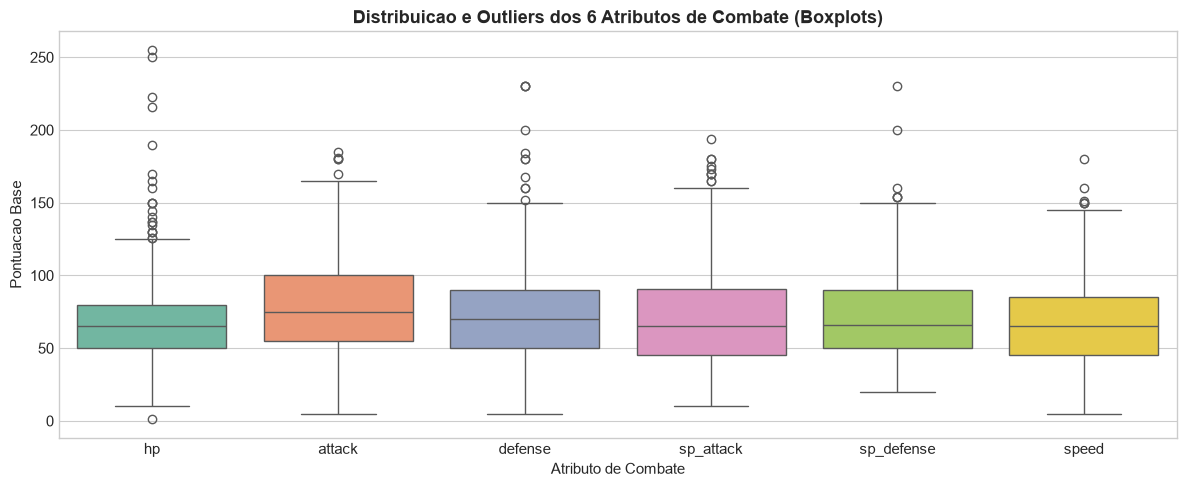

,Atributo,Limite Inferior,Limite Superior,Qtd Outliers,Lendarios entre outliers,Maiores Exemplos
0,hp,5.0,125.0,22,7,"Blissey, Chansey, Guzzlord"
1,attack,-12.5,167.5,5,3,"Heracross, Kartana, Groudon"
2,defense,-10.0,150.0,11,2,"Steelix, Shuckle, Aggron"
3,sp_attack,-24.0,160.0,10,6,"Mewtwo, Kyogre, Rayquaza"
4,sp_defense,-10.0,150.0,6,4,"Shuckle, Regice, Kyogre"
5,speed,-15.0,145.0,6,2,"Deoxys, Ninjask, Pheromosa"


In [6]:
# [IA] Gemini – Deteccao de outliers por IQR e visualizacao em boxplots dos atributos de combate
stats_combate = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df[stats_combate], palette='Set2', ax=ax)
ax.set_title('Distribuicao e Outliers dos 6 Atributos de Combate (Boxplots)', fontsize=13, fontweight='bold')
ax.set_xlabel('Atributo de Combate')
ax.set_ylabel('Pontuacao Base')
plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '7_boxplots_outliers.png'), dpi=150)
plt.show()

resumo_outliers = []
for col in stats_combate:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    mask = (df[col] < lim_inf) | (df[col] > lim_sup)
    exemplos = df[mask].nlargest(3, col)['name'].tolist()
    resumo_outliers.append({
        'Atributo': col,
        'Limite Inferior': round(lim_inf, 1),
        'Limite Superior': round(lim_sup, 1),
        'Qtd Outliers': int(mask.sum()),
        'Lendarios entre outliers': int(df[mask]['is_legendary'].sum()),
        'Maiores Exemplos': ', '.join(exemplos)
    })
display(pd.DataFrame(resumo_outliers))

In [7]:
# [IA] Claude (Antigravity) – Teste de sensibilidade do K-Means (k = 4) a presenca de outliers
from sklearn.metrics import adjusted_rand_score

stats_combate = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
mask_any = np.zeros(len(df), dtype=bool)
for col in stats_combate:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask_any |= ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).to_numpy()

X_all = StandardScaler().fit_transform(df[stats_combate])
lab_all = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_all)

df_sem_out = df.loc[~mask_any, stats_combate]
X_sem = StandardScaler().fit_transform(df_sem_out)
lab_sem = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_sem)

ari = adjusted_rand_score(lab_all[~mask_any], lab_sem)
print(f'Pokemon com outlier em pelo menos 1 atributo: {mask_any.sum()} de {len(df)} ({mask_any.mean()*100:.1f}%)')
print(f'ARI entre os clusters com e sem outliers (mesmos Pokemon): {ari:.3f}')

Pokemon com outlier em pelo menos 1 atributo: 55 de 801 (6.9%)
ARI entre os clusters com e sem outliers (mesmos Pokemon): 0.930


## 4. Análise Exploratória de Dados (EDA)
Exploramos distribuições univariadas e bivariadas das estatísticas dos Pokémons.

**Visualizações exploratórias (4):** histogramas (4.1), frequência por tipo (4.2), matriz de correlação (4.3) e Ataque × Defesa (4.4). Os boxplots da seção 3.2 complementam a análise de outliers.

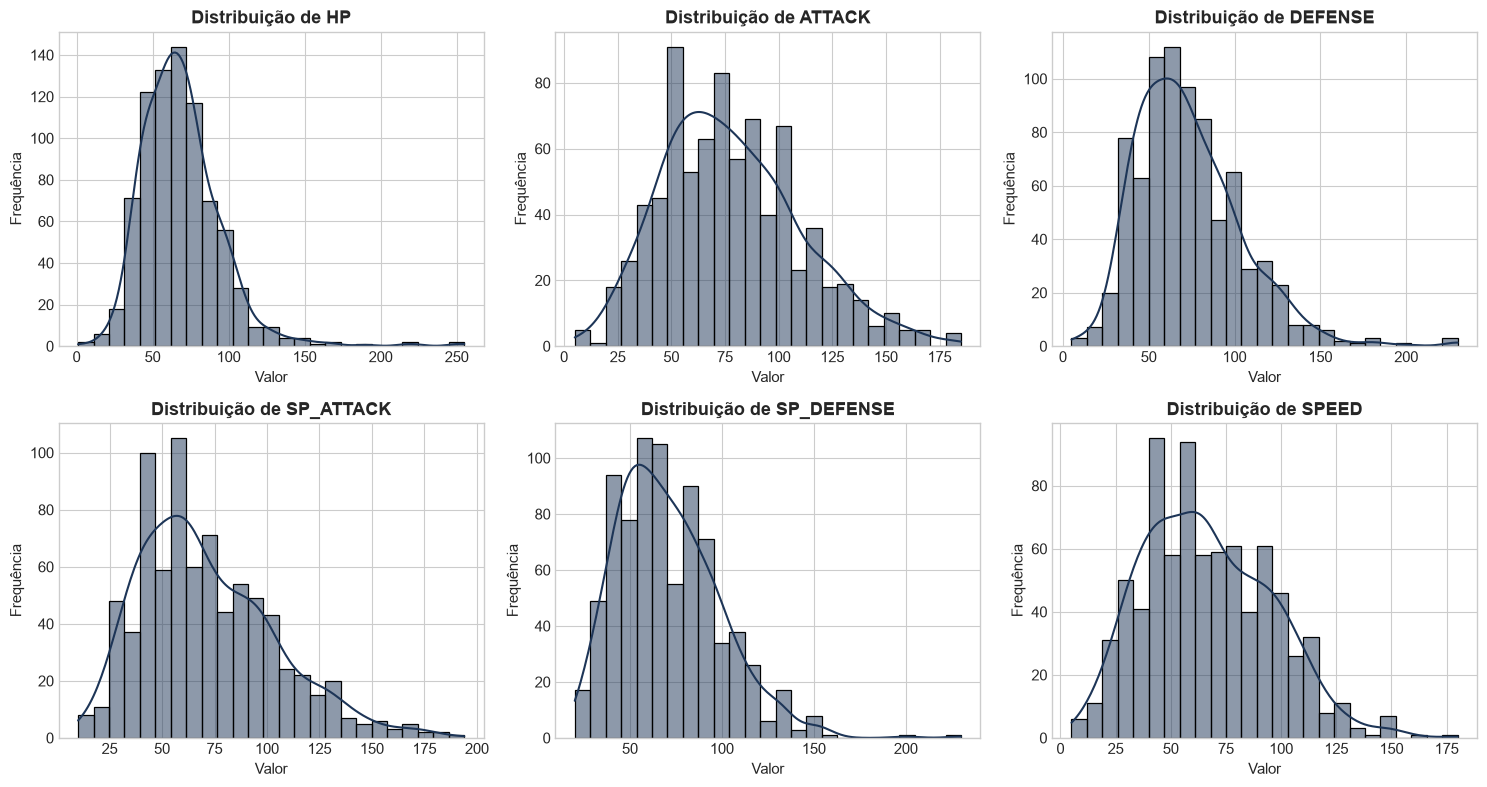

In [8]:
# 4.1 Distribuição dos Atributos de Combate (Histogramas)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
stats_ind = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']

for ax, stat in zip(axes.flatten(), stats_ind):
    sns.histplot(df[stat], kde=True, ax=ax, color='#1d3557', bins=25)
    ax.set_title(f'Distribuição de {stat.upper()}', fontweight='bold')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frequência')

plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '1_distribuicao_stats.png'), dpi=150, bbox_inches='tight')
plt.show()

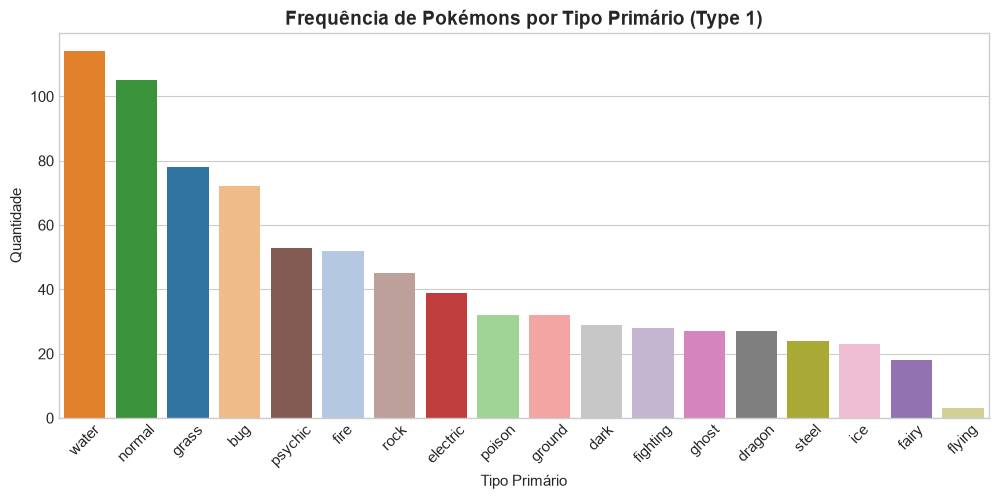

In [9]:
# 4.2 Distribuição de Pokémons por Tipo Primário
plt.figure(figsize=(12, 5))
order_types = df['type1'].value_counts().index
sns.countplot(data=df, x='type1', order=order_types, hue='type1', palette='tab20', legend=False)
plt.title('Frequência de Pokémons por Tipo Primário (Type 1)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Tipo Primário')
plt.ylabel('Quantidade')
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '2_frequencia_tipos.png'), dpi=150, bbox_inches='tight')
plt.show()

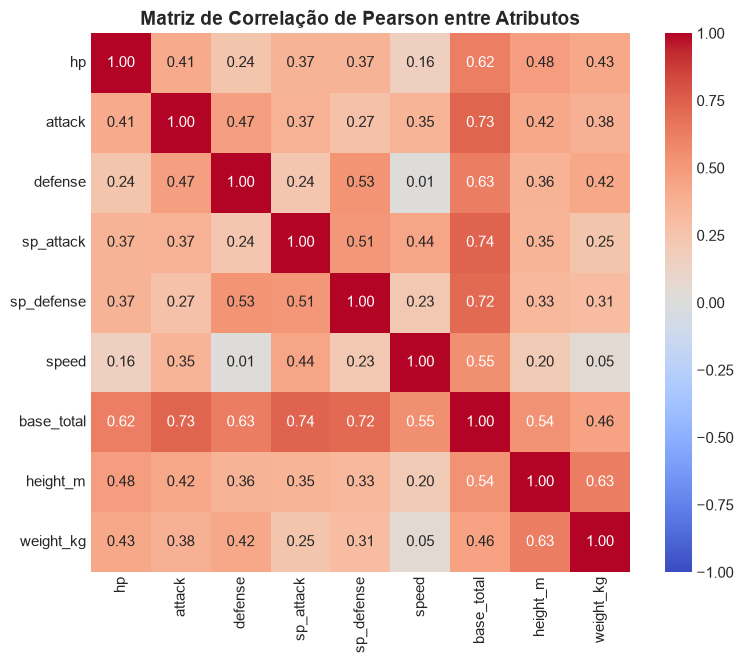

In [10]:
# 4.3 Matriz de Correlação entre Atributos
plt.figure(figsize=(9, 7))
corr = df[combat_stats + ['height_m', 'weight_kg']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlação de Pearson entre Atributos', fontsize=14, fontweight='bold')
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '3_matriz_correlacao.png'), dpi=150, bbox_inches='tight')
plt.show()

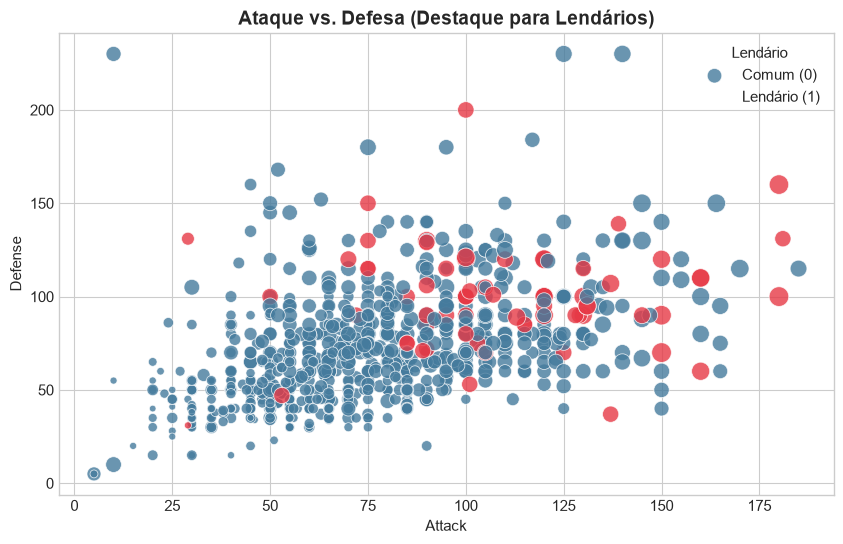

In [11]:
# 4.4 Dispersão: Ataque vs Defesa colorido por Status Lendário
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='attack',
    y='defense',
    hue='is_legendary',
    size='base_total',
    sizes=(20, 200),
    palette={0: '#457b9d', 1: '#e63946'},
    alpha=0.8
)
plt.title('Ataque vs. Defesa (Destaque para Lendários)', fontsize=14, fontweight='bold')
plt.xlabel('Attack')
plt.ylabel('Defense')
plt.legend(title='Lendário', labels=['Comum (0)', 'Lendário (1)'])
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '4_ataque_vs_defesa.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Pré-processamento e Agrupamento com K-Means
Selecionamos as 6 variáveis fundamentais de combate (`hp`, `attack`, `defense`, `sp_attack`, `sp_defense`, `speed`).
Aplicamos o `StandardScaler` para que todas tenham média 0 e variância unitária.

In [12]:
# 5.1 Seleção de features e Padronização
features = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Dados padronizados com sucesso. Shape:', X_scaled.shape)

Dados padronizados com sucesso. Shape: (801, 6)


### 5.2 Avaliação do Número Ótimo de Clusters (Elbow, Silhueta e Davies-Bouldin)

> **Observação:** a curva do cotovelo/silhueta e a projeção PCA (seção 6) são **gráficos técnicos de método**, usados para escolher e validar o k. Eles **não** fazem parte das visualizações explanatórias.

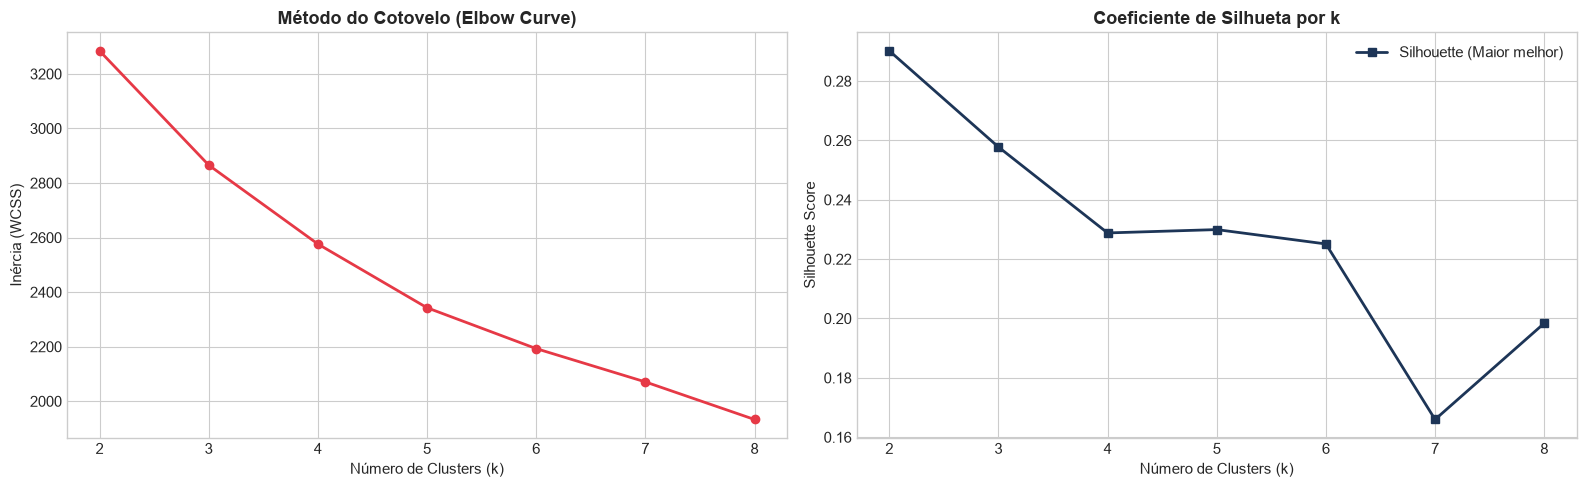

k = 2 | Silhouette Score: 0.2902 | Davies-Bouldin Index: 1.3134
k = 3 | Silhouette Score: 0.2578 | Davies-Bouldin Index: 1.7427
k = 4 | Silhouette Score: 0.2288 | Davies-Bouldin Index: 1.5828
k = 5 | Silhouette Score: 0.2299 | Davies-Bouldin Index: 1.5181
k = 6 | Silhouette Score: 0.2251 | Davies-Bouldin Index: 1.4476
k = 7 | Silhouette Score: 0.1660 | Davies-Bouldin Index: 1.5899
k = 8 | Silhouette Score: 0.1984 | Davies-Bouldin Index: 1.4120


In [13]:
k_values = range(2, 9)
inertias = []
silhouettes = []
davies_bouldins = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    davies_bouldins.append(davies_bouldin_score(X_scaled, labels))

# Gráficos de Avaliação
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Curva do Cotovelo
ax1.plot(k_values, inertias, 'o-', color='#e63946', linewidth=2)
ax1.set_title('Método do Cotovelo (Elbow Curve)', fontweight='bold')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inércia (WCSS)')
ax1.set_xticks(k_values)

# Coeficiente de Silhueta e Davies-Bouldin
ax2.plot(k_values, silhouettes, 's-', color='#1d3557', label='Silhouette (Maior melhor)', linewidth=2)
ax2.set_title('Coeficiente de Silhueta por k', fontweight='bold')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(k_values)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '5_metricas_cotovelo_silhueta.png'), dpi=150, bbox_inches='tight')
plt.show()

for k, s, db in zip(k_values, silhouettes, davies_bouldins):
    print(f'k = {k} | Silhouette Score: {s:.4f} | Davies-Bouldin Index: {db:.4f}')

## 6. Ajuste do Modelo Final (k = 4) e Análise dos Perfis
Com base na análise de cotovelo, silhueta e interpretabilidade de domínio no universo Pokémon, definimos $k = 4$ como um particionamento robusto e bem interpretável.

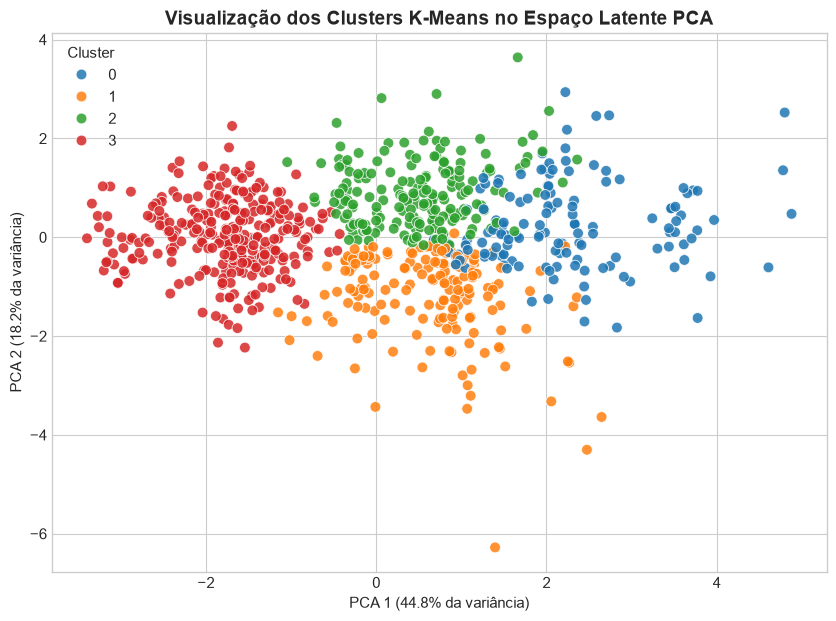

In [14]:
# 6.1 Treinamento do K-Means final com k = 4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans_final.fit_predict(X_scaled)

# Redução de dimensionalidade com PCA (2 componentes) para visualização
pca = PCA(n_components=2, random_state=42)
pca_res = pca.fit_transform(X_scaled)
df['pca1'] = pca_res[:, 0]
df['pca2'] = pca_res[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='tab10',
    alpha=0.85,
    s=60
)
plt.title('Visualização dos Clusters K-Means no Espaço Latente PCA', fontsize=14, fontweight='bold')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)')
plt.legend(title='Cluster')
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '6_clusters_pca.png'), dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# 6.2 Perfil Médio de Atributos por Cluster
cluster_profile = df.groupby('cluster')[features + ['base_total', 'is_legendary']].mean()
cluster_profile['count'] = df.groupby('cluster').size()
cluster_profile['pct_legendary'] = (cluster_profile['is_legendary'] * 100).round(1)
print(cluster_profile.round(1))

# Identificando arquétipos e nomes sugeridos para cada cluster
print('\n--- Interpretação dos Arquétipos dos Clusters ---')
for c in range(4):
    top_pkms = df[df['cluster'] == c]['name'].head(4).tolist()
    b_mean = cluster_profile.loc[c, 'base_total']
    print(f'Cluster {c}: Base Total Média = {b_mean:.1f} | Exemplos: {top_pkms}')

           hp  attack  defense  sp_attack  sp_defense  speed  base_total  \
cluster                                                                    
0        94.7   101.1     90.0      116.7       102.4   84.5       589.4   
1        77.5    91.4    103.9       65.5        82.9   49.3       470.5   
2        71.6    85.6     66.4       79.3        71.0   94.8       468.7   
3        49.8    53.6     50.6       47.8        48.5   49.7       300.0   

         is_legendary  count  pct_legendary  
cluster                                      
0                 0.4    142           40.8  
1                 0.0    176            2.8  
2                 0.0    188            3.2  
3                 0.0    295            0.3  

--- Interpretação dos Arquétipos dos Clusters ---
Cluster 0: Base Total Média = 589.4 | Exemplos: ['Venusaur', 'Charizard', 'Blastoise', 'Pidgeot']
Cluster 1: Base Total Média = 470.5 | Exemplos: ['Wartortle', 'Sandslash', 'Nidoqueen', 'Gloom']
Cluster 2: Base Total

## 7. Visualizações Explanatórias (respondem à pergunta de pesquisa)

> *[IA] Claude (Antigravity) – código dos gráficos explanatórios; escolhas de design discutidas na seção 1.*

As duas visualizações abaixo são voltadas ao público-alvo (não técnico): título declarativo, cinza para o contexto, vermelho apenas para a mensagem e rótulos diretos no lugar de legendas.
- **Explanatória 1:** poder médio por geração — todos os Pokémon vs. apenas os comuns, com a proporção de lendários por geração.
- **Explanatória 2:** participação de cada geração no cluster de maior poder ("Titãs", K-Means k = 4), separando lendários e comuns.


,media_todos,pct_lendarios,media_comuns
generation,,,
1,416.3,3.3,409.1
2,413.2,6.0,400.2
3,420.0,7.4,400.3
4,451.2,12.1,426.7
5,427.0,8.3,410.3
6,437.6,8.3,416.1
7,448.2,21.2,419.4


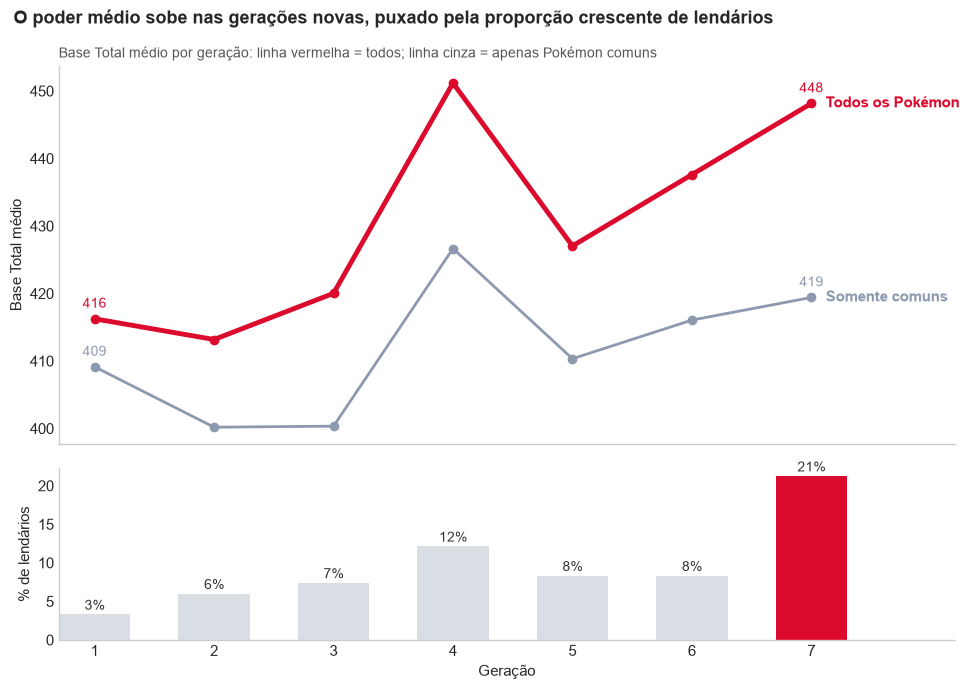

In [16]:
# [IA] Claude (Antigravity) – Explanatoria 1: power creep por geracao (todos vs comuns) + % de lendarios
VERMELHO, CINZA, CINZA_CLARO = '#DC0A2D', '#8D99AE', '#D9DEE5'

por_ger = df.groupby('generation').agg(
    media_todos=('base_total', 'mean'),
    pct_lendarios=('is_legendary', 'mean'))
por_ger['media_comuns'] = df[df['is_legendary'] == 0].groupby('generation')['base_total'].mean()
por_ger['pct_lendarios'] *= 100
display(por_ger.round(1))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2.2, 1]})
ger = por_ger.index

ax1.plot(ger, por_ger['media_comuns'], color=CINZA, lw=2, marker='o')
ax1.plot(ger, por_ger['media_todos'], color=VERMELHO, lw=3.5, marker='o')
ax1.text(ger[-1] + 0.12, por_ger['media_todos'].iloc[-1], 'Todos os Pokémon', color=VERMELHO, va='center', fontweight='bold')
ax1.text(ger[-1] + 0.12, por_ger['media_comuns'].iloc[-1], 'Somente comuns', color=CINZA, va='center', fontweight='bold')
for col, cor in [('media_todos', VERMELHO), ('media_comuns', CINZA)]:
    for g in (ger[0], ger[-1]):
        ax1.annotate(f"{por_ger.loc[g, col]:.0f}", (g, por_ger.loc[g, col]), textcoords='offset points',
                     xytext=(0, 8), ha='center', color=cor, fontsize=10)
ax1.set_ylabel('Base Total médio')
ax1.set_xlim(0.7, 8.2)

cores_barras = [VERMELHO if v == por_ger['pct_lendarios'].max() else CINZA_CLARO for v in por_ger['pct_lendarios']]
ax2.bar(ger, por_ger['pct_lendarios'], color=cores_barras, width=0.6)
for g, v in zip(ger, por_ger['pct_lendarios']):
    ax2.text(g, v + 0.6, f'{v:.0f}%', ha='center', fontsize=10, color='#333333')
ax2.set_ylabel('% de lendários')
ax2.set_xlabel('Geração')
ax2.set_xticks(list(ger))

for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(False)

fig.suptitle('O poder médio sobe nas gerações novas, puxado pela proporção crescente de lendários',
             fontsize=13, fontweight='bold', x=0.02, ha='left')
ax1.set_title('Base Total médio por geração: linha vermelha = todos; linha cinza = apenas Pokémon comuns',
              fontsize=10, color='#555555', loc='left')
plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '8_explanatoria_power_creep.png'), dpi=150, bbox_inches='tight')
plt.show()

Cluster de maior poder (Titas): 0 | membros: 142 | % lendarios no cluster: 40.8%


,titas_lendarios,titas_comuns,titas_total
generation,,,
1,3.3,11.3,14.6
2,6.0,9.0,15.0
3,5.2,10.4,15.6
4,11.2,12.1,23.4
5,7.7,7.7,15.4
6,8.3,13.9,22.2
7,12.5,11.2,23.8


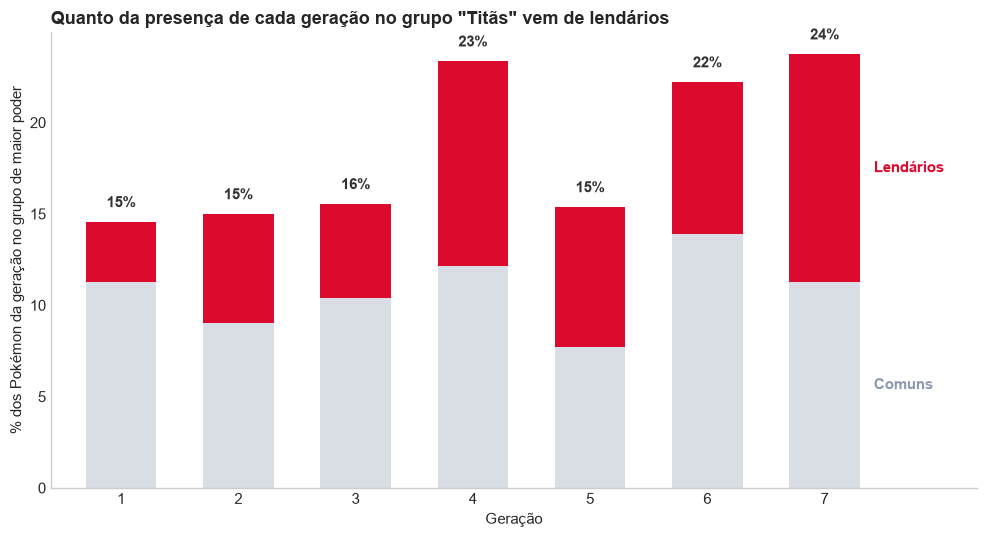

In [17]:
# [IA] Claude (Antigravity) – Explanatoria 2: participacao de cada geracao no cluster de maior poder (Titas)
cluster_titas = df.groupby('cluster')['base_total'].mean().idxmax()
df['titas'] = df['cluster'] == cluster_titas
print(f'Cluster de maior poder (Titas): {cluster_titas} | membros: {df["titas"].sum()} | '
      f'% lendarios no cluster: {df.loc[df["titas"], "is_legendary"].mean()*100:.1f}%')

comp = df.groupby('generation').apply(lambda g: pd.Series({
    'titas_lendarios': (g['titas'] & (g['is_legendary'] == 1)).mean() * 100,
    'titas_comuns': (g['titas'] & (g['is_legendary'] == 0)).mean() * 100,
}), include_groups=False)
comp['titas_total'] = comp.sum(axis=1)
display(comp.round(1))

fig, ax = plt.subplots(figsize=(10, 5.5))
ger = comp.index
ax.bar(ger, comp['titas_comuns'], color=CINZA_CLARO, width=0.6)
ax.bar(ger, comp['titas_lendarios'], bottom=comp['titas_comuns'], color=VERMELHO, width=0.6)
for g in ger:
    ax.text(g, comp.loc[g, 'titas_total'] + 0.8, f"{comp.loc[g, 'titas_total']:.0f}%", ha='center',
            fontweight='bold', color='#333333')

ultima = ger[-1]
ax.text(ultima + 0.42, comp.loc[ultima, 'titas_comuns'] + comp.loc[ultima, 'titas_lendarios'] / 2,
        'Lendários', color=VERMELHO, va='center', fontweight='bold')
ax.text(ultima + 0.42, comp.loc[ultima, 'titas_comuns'] / 2, 'Comuns', color=CINZA, va='center', fontweight='bold')

ax.set_xticks(list(ger))
ax.set_xlim(0.4, 8.3)
ax.set_xlabel('Geração')
ax.set_ylabel('% dos Pokémon da geração no grupo de maior poder')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(False)
ax.set_title('Quanto da presença de cada geração no grupo "Titãs" vem de lendários',
             fontsize=13, fontweight='bold', loc='left')
plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '9_explanatoria_titas_por_geracao.png'), dpi=150, bbox_inches='tight')
plt.show()

## 8. Conclusões e Integração com o Dashboard

1. **Segmentação Natural:** Os 4 clusters representam com clareza:
   - **Cluster de Estágios Iniciais / Baixo Poder:** Pokémons básicos com atributos reduzidos em todas as áreas.
   - **Cluster de Tanques / Defensores:** Elevado HP e Defense, velocidade reduzida.
   - **Cluster de Atacantes Ágeis (Sweepers):** Alto Attack/Sp. Atk e Speed.
   - **Cluster de Titãs / Lendários:** Pokémons com estatísticas superiores e balanceadas, concentrando a grande maioria dos lendários.
2. **Dashboard Interativo:** Todos esses agrupamentos, gráficos e explorações foram integrados no aplicativo interativo construído em Streamlit (`src/parte_especifica/dashboard.py`), permitindo controle dinâmico de hiperparâmetros, filtros de tipos e comparador visual.

## 9. Notas Analíticas Autorais (Obrigatório — Preenchimento do Grupo)

> **[PREENCHER PELO GRUPO — AUTORAL (PROIBIDO IA)]**
> Para cada uma das visualizações (4 exploratórias + 2 explanatórias), registre abaixo:
> 1. **O que está sendo mostrado:**
> 2. **Qual insight pode ser extraído:**
> 3. **Por que este tipo de gráfico foi escolhido (e atributos pré-atentivos usados):**
> 
> - **Visualização Exploratória 1 (Histogramas):** ...
> - **Visualização Exploratória 2 (Frequência de Tipos):** ...
> - **Visualização Exploratória 3 (Matriz de Correlação):** ...
> - **Visualização Exploratória 4 (Ataque vs Defesa):** ...
> - **Visualização Explanatória 1 (Poder médio por geração: todos vs comuns + % de lendários — `8_explanatoria_power_creep.png`):** ...
> - **Visualização Explanatória 2 (Participação de cada geração no cluster "Titãs" — `9_explanatoria_titas_por_geracao.png`):** ...